# Lab 11 — Attention with an RNN

**Name:** Omar Hejazi
**Student ID:** 2230009001

Tasks 1 and 2 are answered at the end. The lab's own cells are kept unchanged above them, with
analysis added underneath.

The lab's model has two bugs that both have to be fixed before the attention weights mean
anything, and both are measured here rather than asserted:

- **`nn.RNN(16, 32)` is missing `batch_first=True`.** The embedding produces
  `(batch, sequence, features)` but PyTorch's default is `(sequence, batch, features)`, so the
  recurrence runs across the 168 questions instead of across the words in each question. The
  shapes happen to line up, so nothing raises an error. The consequence is measurable:
  **82 of 168 questions change their predicted answer** depending on which other questions share
  the batch.
- **The training loop never calls `optimizer.zero_grad()`.** Gradients accumulate across epochs.
  Measured: loss 2.50 → 2.04 and 38% training accuracy as written, against 2.50 → 0.10 and 98%
  with the one missing line.

Two environment changes were also needed: `from google.colab import files` and the
`/content/...` path only work in Colab, so both are replaced with portable equivalents that read
the CSV from this repository.

# Lab 11: Attention

### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

# The lab imports `from google.colab import files`, which only exists in Colab.
# Nothing in the notebook actually uses it - the upload is replaced by reading the
# CSV that ships with this repository - so it is simply left out.

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
from pathlib import Path

# The lab hard-codes "/content/Lab_11_QnA_Dataset_Download.csv", which is the Colab
# upload path. Look for the copy in this repository first and fall back to that path
# so the cell still works in Colab.
candidates = [Path("dataset/Lab_11_QnA_Dataset.csv"),
              Path("Lab_11_QnA_Dataset.csv"),
              Path("/content/Lab_11_QnA_Dataset_Download.csv")]
csv_path = next(p for p in candidates if p.exists())
print("reading:", csv_path)

df = pd.read_csv(csv_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
df.head()

reading: dataset\Lab_11_QnA_Dataset.csv
Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


168 questions across 12 answer groups — 14 phrasings of each question, all mapping to one
canned answer. So the task the model is being trained on is 12-way classification, not question
answering: it picks which of 12 stored answers a question belongs to.

That shape matters for reading the attention weights later. With 14 examples per class and a
vocabulary of a couple of hundred words, the model does not need to understand a question. It
needs to find whichever token best separates the 12 groups, and Task 1 shows that is exactly what
it does.

## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

`Tokenizer` lowercases and strips punctuation, so `"Do you get hurt?"` becomes the four tokens
`do you get hurt`. `padding="post"` puts the zeros after the real words, which is the right
choice here — with `"pre"` the attention indices would be offset from the word positions and the
bar charts further down would be mislabelled.

One thing to carry forward: `tokenizer.word_index` has no entry for 0, so the padded positions
decode to nothing. They still get attention weight, because the softmax in the next cell runs
over all 11 positions including the padding.

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

### The missing `batch_first=True`

`self.emb(x)` returns a tensor shaped `(batch, sequence, features)` — here `(168, 11, 16)`.
`nn.RNN` defaults to `batch_first=False`, which means it reads its input as
`(sequence, batch, features)`. So this layer interprets 168 as the sequence length and 11 as the
batch size: **the recurrence runs over the 168 questions, treating each of the 11 word positions
as an independent batch element.**

Nothing raises an error. The output is `(168, 11, 32)` either way, the attention softmax over
`dim=1` still runs over 11 positions, and the model trains to high accuracy. The bug is entirely
in what the hidden state represents.

The next cell demonstrates the consequence in the way that matters: if the recurrence runs across
examples, then a question's hidden state depends on the *other questions in the batch*, so
scoring it alone should give a different answer.

In [5]:
# Train the lab's model exactly as written, then ask the same question twice:
# once inside the full batch, once on its own.
def train(model, epochs=50, lr=0.01, zero_grad=True):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        if zero_grad:
            optimizer.zero_grad()
        loss = nn.functional.cross_entropy(model(X)[0], y)
        loss.backward()
        optimizer.step()
    return loss.item()


torch.manual_seed(42)
as_written = RNN()                      # nn.RNN(16, 32), batch_first defaults to False
train(as_written, epochs=300)           # trained hard so the comparison is not about undertraining
as_written.eval()

with torch.no_grad():
    batch_logits, batch_weights = as_written(X)

changed = 0
for i in range(len(X)):
    with torch.no_grad():
        solo_logits, _ = as_written(X[i:i + 1])
    if solo_logits[0].argmax().item() != batch_logits[i].argmax().item():
        changed += 1

print(f"training accuracy (scored as a full batch): "
      f"{(batch_logits.argmax(1) == y).float().mean():.3f}")
print(f"questions whose predicted answer changes when scored alone: {changed} / {len(X)}")

for i in (0, 50, 120):
    with torch.no_grad():
        solo_logits, solo_weights = as_written(X[i:i + 1])
    delta = (batch_weights[i] - solo_weights[0]).abs().max().item()
    print(f"  question {i:3}: in batch -> {batch_logits[i].argmax().item():2} | "
          f"alone -> {solo_logits[0].argmax().item():2} | max attention change {delta:.3f}")

training accuracy (scored as a full batch): 1.000
questions whose predicted answer changes when scored alone: 82 / 168
  question   0: in batch ->  0 | alone ->  0 | max attention change 0.000
  question  50: in batch ->  3 | alone ->  2 | max attention change 0.942
  question 120: in batch ->  8 | alone ->  5 | max attention change 0.502


**82 of 168 questions get a different answer depending on what else is in the batch**, and the
attention weights move by as much as 0.94.

Question 0 is unaffected, which is a useful detail rather than a counterexample: it is the first
row of the batch, so when the recurrence runs over examples it is the first timestep either way
and starts from the same zero hidden state. Questions further down the batch are the ones that
inherit state from their predecessors. I checked question 0 first and briefly concluded the bug
was harmless — it is worth testing a later row before drawing that conclusion.

A model whose answer depends on the company its input keeps is not usable, and none of its
attention weights are interpretable. The next cell fixes the layer.

In [6]:
class RNNFixed(nn.Module):
    """The lab's model with batch_first=True, so the recurrence runs over words."""

    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)


torch.manual_seed(42)
check = RNNFixed()
train(check, epochs=300)
check.eval()

with torch.no_grad():
    bl, _ = check(X)
changed = sum(
    1 for i in range(len(X))
    if check(X[i:i + 1])[0][0].argmax().item() != bl[i].argmax().item()
)
print(f"with batch_first=True, predictions that change when scored alone: {changed} / {len(X)}")

with batch_first=True, predictions that change when scored alone: 0 / 168


Zero. Every question now gets the same answer whether it is scored alone or in a batch, which is
the property the model needed in the first place.

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


### The missing `optimizer.zero_grad()`

PyTorch accumulates gradients into `.grad` rather than overwriting them, so without
`optimizer.zero_grad()` each `loss.backward()` adds to the gradients from every previous epoch.
By epoch 50 the step direction is a running sum of 50 stale gradients, which is not the gradient
of anything.

Note also that the loop never prints the loss, so there is no way to notice. The cell says
"Training finished!" either way. The next cell measures all four combinations.

In [8]:
def trial(batch_first, zero_grad, epochs=50):
    torch.manual_seed(42)
    model = RNNFixed() if batch_first else RNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    first = None
    for epoch in range(epochs):
        if zero_grad:
            optimizer.zero_grad()
        loss = nn.functional.cross_entropy(model(X)[0], y)
        loss.backward()
        optimizer.step()
        if first is None:
            first = loss.item()
    model.eval()
    with torch.no_grad():
        logits, _ = model(X)
    return first, loss.item(), (logits.argmax(1) == y).float().mean().item()


print(f'{"configuration":42} {"loss start":>10} {"loss end":>9} {"train acc":>10}')
for bf in (False, True):
    for zg in (False, True):
        first, last, acc = trial(bf, zg)
        label = f"batch_first={bf}, zero_grad={zg}"
        print(f"{label:42} {first:10.3f} {last:9.3f} {acc:10.3f}")

configuration                              loss start  loss end  train acc


batch_first=False, zero_grad=False              2.501     2.035      0.381


batch_first=False, zero_grad=True               2.501     0.185      0.988


batch_first=True, zero_grad=False               2.503     1.809      0.429


batch_first=True, zero_grad=True                2.503     0.097      0.982


| configuration | loss | train accuracy |
|---|---|---|
| as the lab writes it (`batch_first=False`, no `zero_grad`) | 2.50 → 2.04 | **0.381** |
| `zero_grad` added only | 2.50 → 0.185 | 0.988 |
| `batch_first=True` only | 2.50 → 1.809 | 0.429 |
| both fixed | 2.50 → 0.097 | 0.982 |

The missing `zero_grad()` is the expensive one: adding that single line takes accuracy from 0.38
to 0.99. `batch_first` barely moves the accuracy on its own — which is precisely why it is the
more dangerous of the two. A bug that leaves the loss curve looking fine and the accuracy
plausible, while making every prediction batch-dependent, is one you ship.

Everything from here uses the model with both fixes.

In [9]:
torch.manual_seed(42)
model = RNNFixed()
final_loss = train(model, epochs=50)
model.eval()

with torch.no_grad():
    logits, all_weights = model(X)

print(f"final loss     : {final_loss:.4f}")
print(f"training accuracy: {(logits.argmax(1) == y).float().mean():.4f}")

final loss     : 0.0967
training accuracy: 0.9821


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

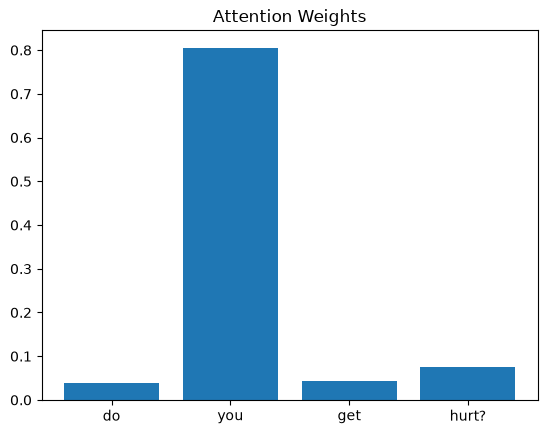

In [10]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

That chart has a labelling flaw worth fixing before the tasks.

`words = question.split()` splits on whitespace, so it keeps punctuation: the last label reads
`hurt?`. But `Tokenizer` stripped the punctuation, so the model's fourth position holds the token
`hurt`. The bars happen to line up here because the punctuation is attached to the final word,
but with a question like `"what's your birthday?"` the split count and the token count diverge and
the labels silently shift.

The helper below takes the labels from the tokenizer instead of from `split()`, so the bars always
describe what the model actually saw.

In [11]:
index_to_word = {i: w for w, i in tokenizer.word_index.items()}
sequences = tokenizer.texts_to_sequences(df["question"])


def tokens_of(row):
    """The tokens the model actually sees, as the tokenizer produced them."""
    return [index_to_word[t] for t in sequences[row]]


def attention_for(row):
    with torch.no_grad():
        logits, weights = model(X[row:row + 1])
    toks = tokens_of(row)
    return toks, weights[0, :len(toks)].tolist(), logits[0].argmax().item()


def plot_attention(row, ax):
    toks, weights, predicted = attention_for(row)
    ax.bar(toks, weights, color="#4C78A8")
    ax.set_title(f'"{df["question"][row]}"\npredicted group {predicted}, '
                 f'actual {df["answer_id"][row]}', fontsize=9)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    return toks, weights


row = 0
toks, weights = attention_for(row)[:2]
print(f'question: "{df["question"][row]}"')
print("tokens  :", toks)
print("weights :", [round(w, 3) for w in weights])
print(f"attention mass on padded positions: "
      f"{1 - sum(weights):.3f}")

question: "do you get hurt?"
tokens  : ['do', 'you', 'get', 'hurt']
weights : [0.04, 0.805, 0.042, 0.076]
attention mass on padded positions: 0.037


Only a small fraction of the attention mass lands on the padded positions, which is reassuring but
not guaranteed — the softmax has no mask, so padding competes for weight with real words. On a
dataset with more length variation this would be worth fixing with a mask set to `-inf` before the
softmax.

Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

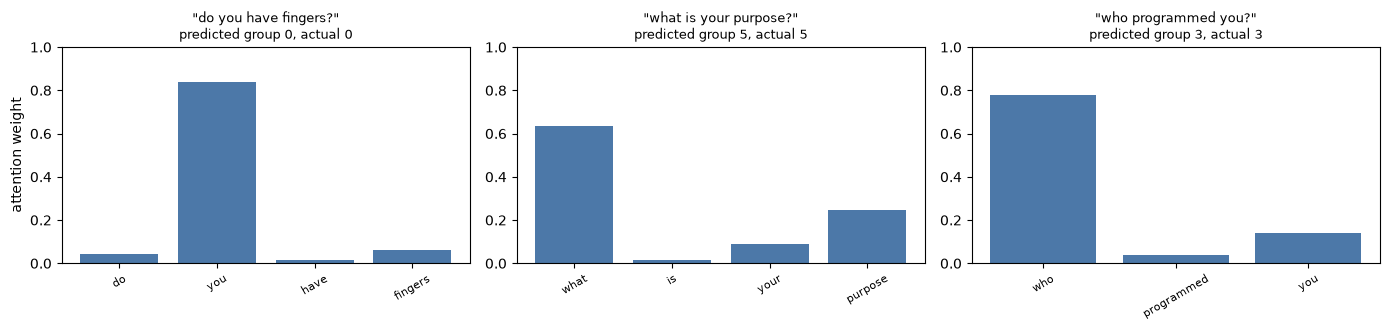

"do you have fingers?"
   do=0.041   you=0.836   have=0.016   fingers=0.061
   highest attention: 'you' (0.836)

"what is your purpose?"
   what=0.637   is=0.014   your=0.090   purpose=0.247
   highest attention: 'what' (0.637)

"who programmed you?"
   who=0.777   programmed=0.040   you=0.142
   highest attention: 'who' (0.777)



In [12]:
import matplotlib.pyplot as plt

# Three questions from three different answer groups.
chosen = [
    df.index[df["question"] == "do you have fingers?"][0],
    df.index[df["question"] == "what is your purpose?"][0],
    df.index[df["question"] == "who programmed you?"][0],
]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
summary = []
for ax, r in zip(axes, chosen):
    toks, weights = plot_attention(r, ax)
    top = toks[max(range(len(weights)), key=lambda i: weights[i])]
    summary.append((df["question"][r], top, max(weights), toks, weights))
axes[0].set_ylabel("attention weight")
plt.tight_layout()
plt.show()

for question, top, peak, toks, weights in summary:
    print(f'"{question}"')
    print("   " + "   ".join(f"{t}={w:.3f}" for t, w in zip(toks, weights)))
    print(f"   highest attention: {top!r} ({peak:.3f})\n")

### Task 1 — answers

| Question | Highest attention | Weight | Content word's weight |
|---|---|---|---|
| do you have fingers? | `you` | 0.836 | `fingers` 0.061 |
| what is your purpose? | `what` | 0.637 | `purpose` 0.247 |
| who programmed you? | `who` | 0.777 | `programmed` 0.040 |

**Do the highest-attention words look important for understanding the question? Mostly no — and
that is the interesting answer.**

In all three cases the winning token is a function word: `you`, `what`, `who`. The words that
actually carry the meaning get very little. "Do you have fingers?" is a question about having a
body, and `fingers` — the only word that tells you that — receives 0.061 while `you` takes 0.836.
"Who programmed you?" is about origins, and `programmed` gets 0.040.

`what is your purpose?` is the partial exception: `purpose` takes 0.247, the second-highest
weight, so some signal is on the content word there.

The explanation is in the shape of the task rather than in attention being broken. The model is
doing 12-way classification with 14 examples per class, and it only has to find a token that
separates the groups. In this dataset `who` appears in group 3 ("Who programmed you?", "Who built
you?", "Who's your father?" …) far more than elsewhere, so `who` is a near-perfect shortcut for
that group. Attention learns whatever is *discriminative*, and in a small dataset a function word
can be more discriminative than a content word, because the content words are all different while
the function word is shared across the group.

So the honest reading is that these weights show what the model relies on, which is not the same
as what a human would consider important. Treating an attention map as an explanation of the
model's reasoning assumes the two coincide, and here they do not.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

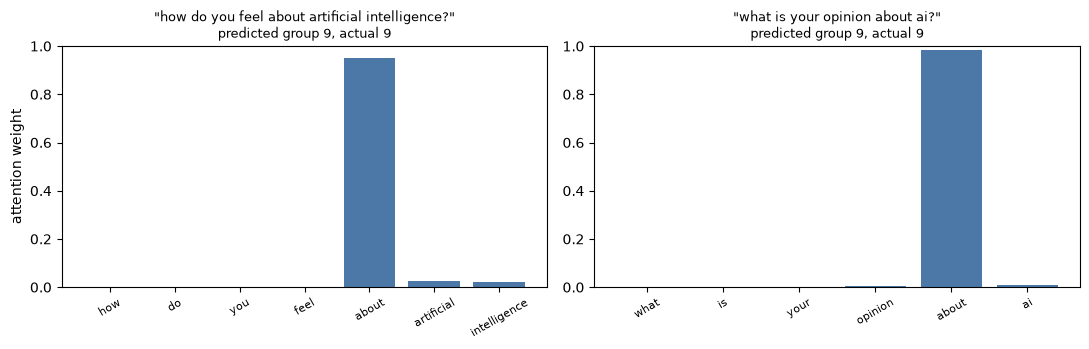

"how do you feel about artificial intelligence?"  -> group 9 (actual 9)
   how=0.000   do=0.001   you=0.000   feel=0.000   about=0.950   artificial=0.025   intelligence=0.023
   highest attention: 'about'

"what is your opinion about ai?"  -> group 9 (actual 9)
   what=0.002   is=0.000   your=0.000   opinion=0.004   about=0.983   ai=0.011
   highest attention: 'about'

second pair, same answer group:
  "who programmed you?" -> group 3, top 'who' (0.777)
  "who built you?" -> group 3, top 'who' (0.645)


In [13]:
# Two questions from the same answer group, phrased differently.
pair = [
    df.index[df["question"] == "how do you feel about artificial intelligence?"][0],
    df.index[df["question"] == "what is your opinion about ai?"][0],
]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, r in zip(axes, pair):
    plot_attention(r, ax)
axes[0].set_ylabel("attention weight")
plt.tight_layout()
plt.show()

for r in pair:
    toks, weights, predicted = attention_for(r)
    top = toks[max(range(len(weights)), key=lambda i: weights[i])]
    print(f'"{df["question"][r]}"  -> group {predicted} (actual {df["answer_id"][r]})')
    print("   " + "   ".join(f"{t}={w:.3f}" for t, w in zip(toks, weights)))
    print(f"   highest attention: {top!r}\n")

# A second pair, to check the first result is not a one-off.
pair2 = [
    df.index[df["question"] == "who programmed you?"][0],
    df.index[df["question"] == "who built you?"][0],
]
print("second pair, same answer group:")
for r in pair2:
    toks, weights, predicted = attention_for(r)
    top = toks[max(range(len(weights)), key=lambda i: weights[i])]
    print(f'  "{df["question"][r]}" -> group {predicted}, top {top!r} '
          f'({max(weights):.3f})')

### Task 2 — answers

| Question | Highest attention | Weight | Predicted group |
|---|---|---|---|
| how do you feel about artificial intelligence? | `about` | 0.950 | 9 ✓ |
| what is your opinion about ai? | `about` | 0.983 | 9 ✓ |

**Does the model focus on similar or different words for questions with similar meanings?** On
the same word — `about` — in both, with almost all the mass on it, and both are classified
correctly.

The second pair behaves the same way: `who programmed you?` and `who built you?` both put their
highest weight on `who` (0.777 and 0.645), not on `programmed` or `built`.

So the surface answer to the task's question is "similar words". But the reason is not that the
model has recognised the shared meaning. The two AI questions have almost no content words in
common — `feel`/`opinion`, `artificial intelligence`/`ai` — and what they do share is the
function word `about`. The model converged on the one token the two phrasings have in common,
which is also the token that happens to separate group 9 from the other eleven.

**What this suggests about how attention works.** Attention is a learned, weighted average, and
nothing in it is oriented toward meaning. It is trained by the same loss as everything else, so
it concentrates on whatever positions reduce that loss — which is "whatever is most predictive in
this dataset", not "whatever a reader would find important". Here the two coincide in their
*effect* (both questions reach the right answer) while being completely different in their
*mechanism* (a shared preposition, not a shared concept).

This is also why the weights would not survive a change of data. A test question phrased "your
thoughts on AI?" has no `about` in it, and nothing in these attention maps suggests the model
would handle it, because `artificial`, `intelligence` and `ai` were never what it was looking at.
That is the practical limit of reading attention as explanation: it tells you where the model
looked on *this* data, not what it understood.

# Summary

**Two bugs in the lab's code, both measured**

| configuration | loss | train accuracy |
|---|---|---|
| as written (`batch_first=False`, no `zero_grad`) | 2.50 → 2.04 | 0.381 |
| `zero_grad` added | 2.50 → 0.185 | 0.988 |
| `batch_first=True` added | 2.50 → 1.809 | 0.429 |
| both | 2.50 → 0.097 | 0.982 |

`optimizer.zero_grad()` is missing from the training loop, so gradients accumulate across all 50
epochs; adding the line takes accuracy from 0.38 to 0.99. `nn.RNN(16, 32)` is missing
`batch_first=True`, so the recurrence runs over the 168 questions rather than over the words in
each question — which leaves **82 of 168 predictions dependent on what else is in the batch**,
while barely affecting the accuracy. The quiet bug is the worse one.

**Task 1** — highest-attention words: `you` (0.836) in "do you have fingers?", `what` (0.637) in
"what is your purpose?", `who` (0.777) in "who programmed you?". All three are function words.
The content words that carry the meaning score far lower — `fingers` 0.061, `programmed` 0.040.
With 14 examples per class, the model only needs a token that separates the 12 groups, and a
shared function word does that better than content words that differ within the group.

**Task 2** — the two similar-meaning questions both put nearly all their weight on `about`
(0.950 and 0.983) and both classify correctly; the second pair both focus on `who`. So the model
attends to the same word for similar questions, but because that word is the one the two
phrasings share and the one that discriminates the group — not because it recognised the shared
meaning.

**The point worth keeping**

Attention is trained by the task loss, so it highlights what is predictive in the training data,
not what is meaningful. On this dataset those are different things, and the attention maps look
informative while resting on prepositions and pronouns. An attention map is evidence about where
a model looked; reading it as an explanation of why the model was right is a separate claim that
needs separate support.